# 03 — Cross-Approach Comparison
## Multilingual vs Translate-then-Classify for Sentiment Analysis

With both approaches trained and evaluated, it's time to put them head to head: Notebook 01's multilingual models against Notebook 02's translate-then-classify models. I'm pulling in the saved results from both (`Results_Multilingual/` and `Results_Translated/`) to figure out which strategy actually holds up better, and writing the unified comparison out to `Results_Comparison/`.


## Setup


In [1]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

from google.colab import drive
drive.mount('/content/drive')

DRIVE_BASE = '/content/drive/MyDrive/ML_Sentiment_Analysis'
MULTI_DIR = f'{DRIVE_BASE}/Results_Multilingual'
TRANS_DIR = f'{DRIVE_BASE}/Results_Translated'
COMP_DIR = f'{DRIVE_BASE}/Results_Comparison'
os.makedirs(COMP_DIR, exist_ok=True)

print(f'Multilingual results: {MULTI_DIR}')
print(f'Translated results:   {TRANS_DIR}')
print(f'Comparison output:    {COMP_DIR}')

Mounted at /content/drive
Multilingual results: /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Multilingual
Translated results:   /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Translated
Comparison output:    /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Comparison


## Loading all the results


In [2]:
def load_json(path):
    with open(path, 'r') as f:
        return json.load(f)

# Load model results
results = {}
files = {
    'BERT+BiLSTM (Multi)': f'{MULTI_DIR}/bert_bilstm_multilingual_results.json',
    'XLM-RoBERTa': f'{MULTI_DIR}/xlm_roberta_results.json',
    'BERT+BiLSTM (EN)': f'{TRANS_DIR}/bert_bilstm_english_results.json',
    'RoBERTa (EN)': f'{TRANS_DIR}/roberta_english_results.json',
}

for name, path in files.items():
    if os.path.exists(path):
        results[name] = load_json(path)
        print(f'✓ Loaded: {name}')
    else:
        print(f'✗ Missing: {path}')

# Load polarity results
polarity_multi = load_json(f'{MULTI_DIR}/overall_polarity_multilingual.json') if os.path.exists(f'{MULTI_DIR}/overall_polarity_multilingual.json') else {}
polarity_trans = load_json(f'{TRANS_DIR}/overall_polarity_translated.json') if os.path.exists(f'{TRANS_DIR}/overall_polarity_translated.json') else {}

print(f'\nLoaded {len(results)} model results.')

✓ Loaded: BERT+BiLSTM (Multi)
✓ Loaded: XLM-RoBERTa
✓ Loaded: BERT+BiLSTM (EN)
✓ Loaded: RoBERTa (EN)

Loaded 4 model results.


## Performance summary


In [3]:
# Build comparison DataFrame
rows = []
for name, r in results.items():
    m = r['metrics']
    approach = 'Multilingual' if 'Multi' in name or 'XLM' in name else 'Translated'
    rows.append({
        'Model': name,
        'Approach': approach,
        'Accuracy': m['accuracy'],
        'F1 (macro)': m['f1_macro'],
        'F1 (weighted)': m['f1_weighted'],
        'AUC-ROC': m['auc_roc_macro'],
        'Training Time (s)': m['training_time_seconds'],
        'Epochs': r['hyperparameters']['epochs_trained'],
    })

df_comp = pd.DataFrame(rows)
print('=' * 80)
print('CROSS-APPROACH COMPARISON — ALL MODELS')
print('=' * 80)
print(df_comp.to_string(index=False))
print('=' * 80)

# Rankings
print('\n--- Rankings ---')
for metric in ['Accuracy', 'F1 (macro)', 'AUC-ROC']:
    ranked = df_comp.sort_values(metric, ascending=False)['Model'].tolist()
    print(f'{metric}: {" > ".join(ranked)}')
fastest = df_comp.sort_values('Training Time (s)')['Model'].tolist()
print(f'Speed: {" > ".join(fastest)}')

CROSS-APPROACH COMPARISON — ALL MODELS
              Model     Approach  Accuracy  F1 (macro)  F1 (weighted)  AUC-ROC  Training Time (s)  Epochs
BERT+BiLSTM (Multi) Multilingual  0.977778    0.978585       0.977815 0.997678         268.649384      15
        XLM-RoBERTa Multilingual  0.981481    0.981497       0.981512 0.999727         192.016272      10
   BERT+BiLSTM (EN)   Translated  0.996296    0.996166       0.996295 0.999913         122.360644       8
       RoBERTa (EN)   Translated  0.996296    0.996166       0.996295 1.000000         138.611577       8

--- Rankings ---
Accuracy: RoBERTa (EN) > BERT+BiLSTM (EN) > XLM-RoBERTa > BERT+BiLSTM (Multi)
F1 (macro): RoBERTa (EN) > BERT+BiLSTM (EN) > XLM-RoBERTa > BERT+BiLSTM (Multi)
AUC-ROC: RoBERTa (EN) > BERT+BiLSTM (EN) > XLM-RoBERTa > BERT+BiLSTM (Multi)
Speed: BERT+BiLSTM (EN) > RoBERTa (EN) > XLM-RoBERTa > BERT+BiLSTM (Multi)


## Visualizing the comparison


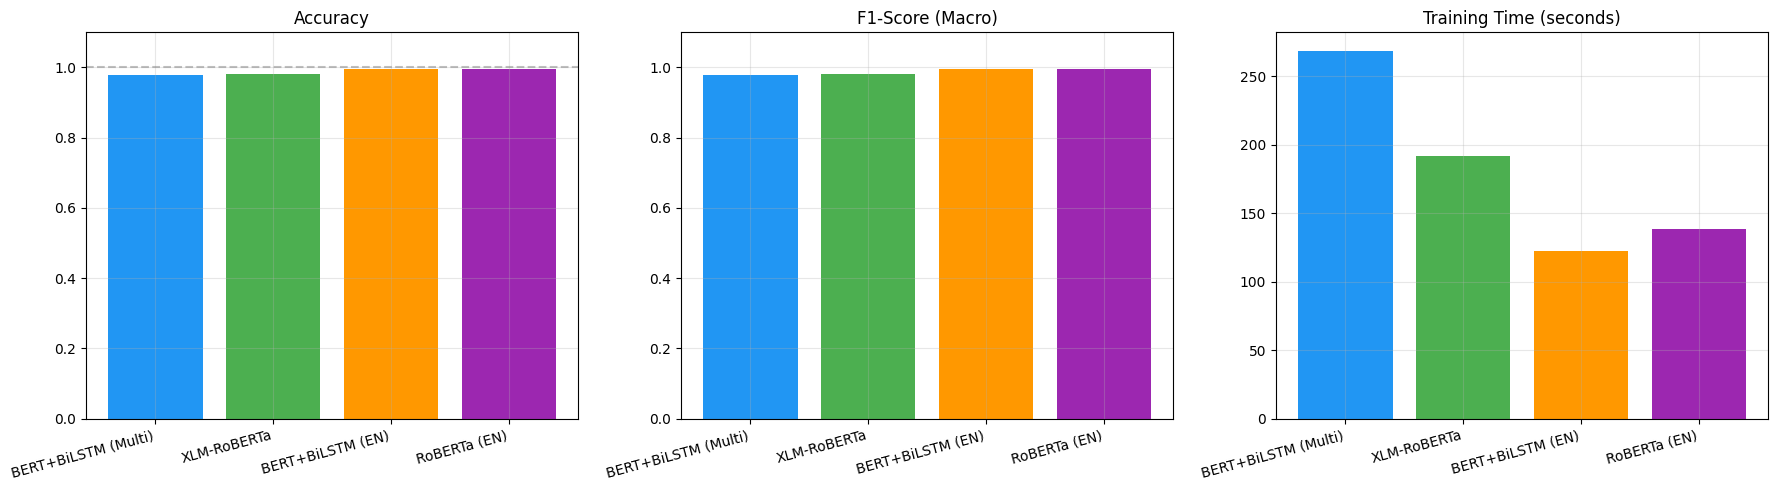

In [4]:
# Bar chart: Metrics comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = df_comp['Model'].tolist()
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']
x = np.arange(len(models))

# Accuracy
axes[0].bar(x, df_comp['Accuracy'], color=colors)
axes[0].set_xticks(x); axes[0].set_xticklabels(models, rotation=15, ha='right')
axes[0].set_ylim(0, 1.1); axes[0].set_title('Accuracy'); axes[0].grid(True, alpha=0.3)
axes[0].axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)

# F1 macro
axes[1].bar(x, df_comp['F1 (macro)'], color=colors)
axes[1].set_xticks(x); axes[1].set_xticklabels(models, rotation=15, ha='right')
axes[1].set_ylim(0, 1.1); axes[1].set_title('F1-Score (Macro)'); axes[1].grid(True, alpha=0.3)

# Training time
axes[2].bar(x, df_comp['Training Time (s)'], color=colors)
axes[2].set_xticks(x); axes[2].set_xticklabels(models, rotation=15, ha='right')
axes[2].set_title('Training Time (seconds)'); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{COMP_DIR}/comparison_metrics_bars.png', dpi=150, bbox_inches='tight')
plt.show()

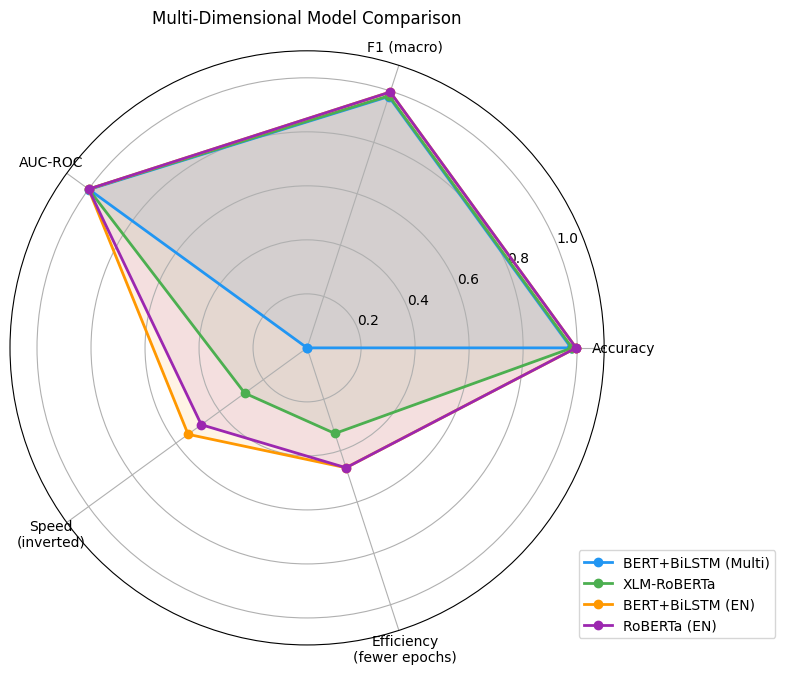

In [5]:
# Radar chart
categories = ['Accuracy', 'F1 (macro)', 'AUC-ROC', 'Speed\n(inverted)', 'Efficiency\n(fewer epochs)']
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

max_time = df_comp['Training Time (s)'].max()
max_epochs = df_comp['Epochs'].max()

for i, (_, row) in enumerate(df_comp.iterrows()):
    values = [
        row['Accuracy'],
        row['F1 (macro)'],
        row['AUC-ROC'],
        1 - (row['Training Time (s)'] / max_time) if max_time > 0 else 1,
        1 - (row['Epochs'] / max_epochs) if max_epochs > 0 else 1,
    ]
    values.append(values[0])  # close the polygon
    angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
    angles.append(angles[0])
    ax.plot(angles, values, 'o-', linewidth=2, label=row['Model'], color=colors[i])
    ax.fill(angles, values, alpha=0.1, color=colors[i])

ax.set_xticks(np.linspace(0, 2 * np.pi, len(categories), endpoint=False))
ax.set_xticklabels(categories)
ax.set_ylim(0, 1.1)
ax.legend(loc='lower right', bbox_to_anchor=(1.3, 0))
ax.set_title('Multi-Dimensional Model Comparison', pad=20)
plt.tight_layout()
plt.savefig(f'{COMP_DIR}/comparison_radar.png', dpi=150, bbox_inches='tight')
plt.show()

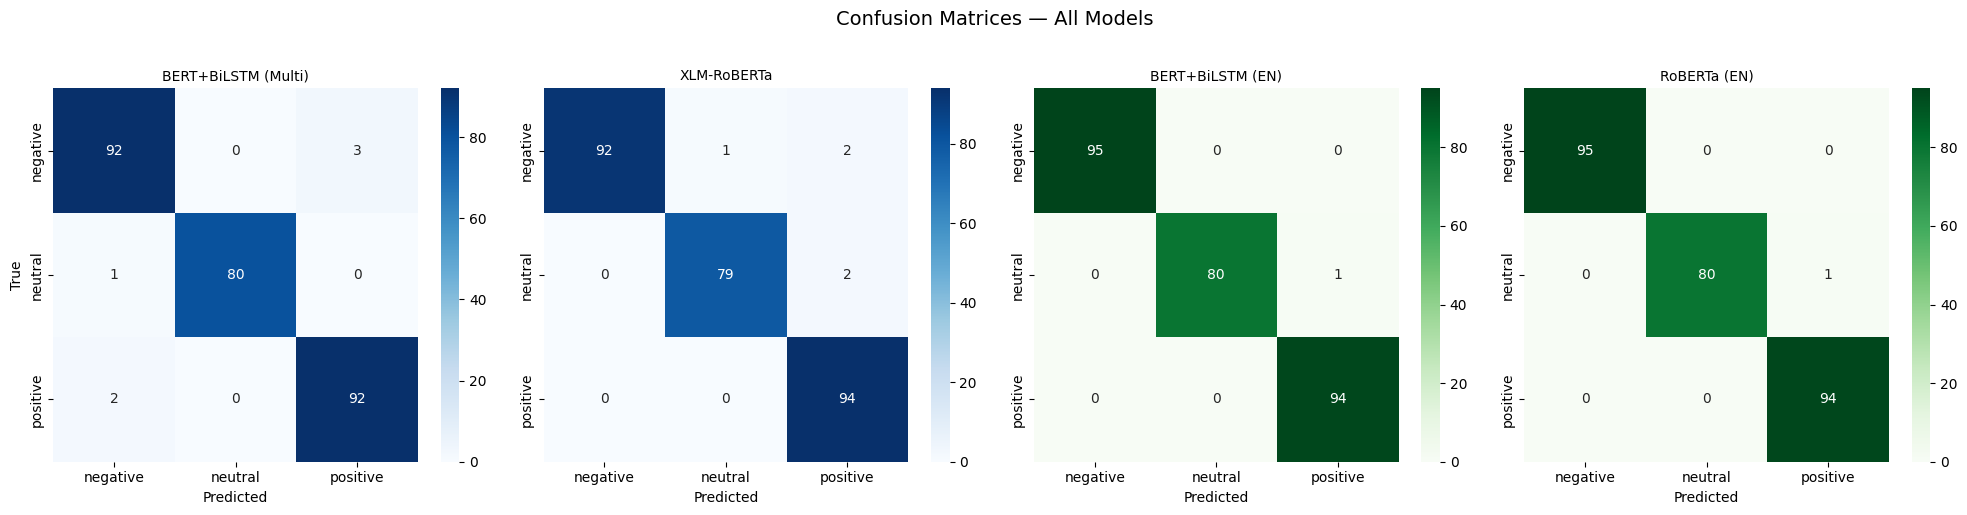

In [6]:
# Side-by-side confusion matrices
fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 5))
if len(results) == 1:
    axes = [axes]

for i, (name, r) in enumerate(results.items()):
    cm = np.array(r['confusion_matrix'])
    class_names = r.get('dataset', {}).get('class_names', ['neg', 'neu', 'pos'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues' if i < 2 else 'Greens',
                xticklabels=class_names, yticklabels=class_names, ax=axes[i])
    axes[i].set_title(name, fontsize=10)
    axes[i].set_ylabel('True' if i == 0 else '')
    axes[i].set_xlabel('Predicted')

plt.suptitle('Confusion Matrices — All Models', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f'{COMP_DIR}/comparison_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

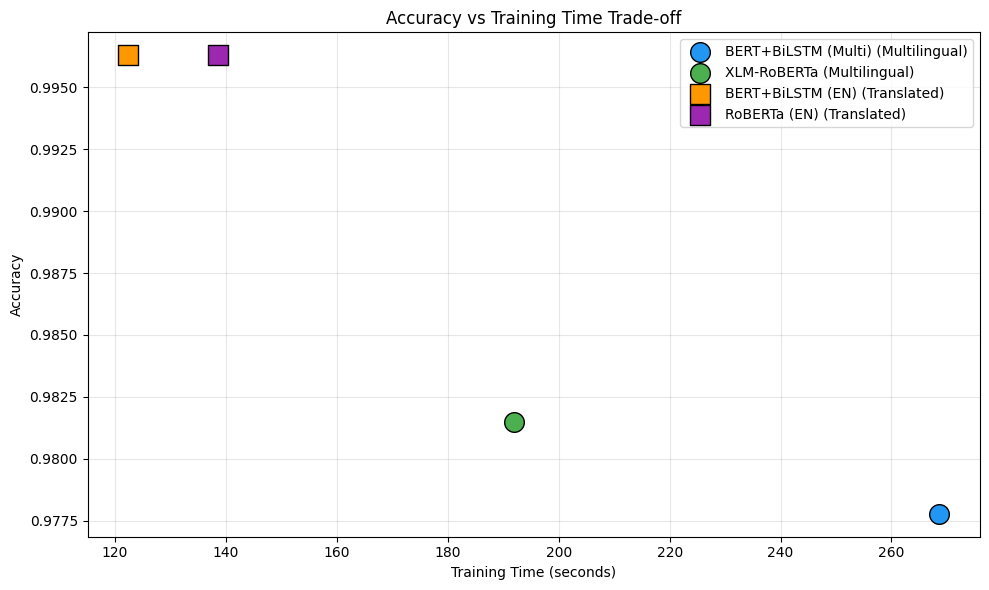

In [7]:
# Accuracy vs Training Time scatter
fig, ax = plt.subplots(figsize=(10, 6))
for i, (_, row) in enumerate(df_comp.iterrows()):
    marker = 'o' if row['Approach'] == 'Multilingual' else 's'
    ax.scatter(row['Training Time (s)'], row['Accuracy'], s=200, c=colors[i],
               marker=marker, label=f"{row['Model']} ({row['Approach']})", zorder=5, edgecolors='black')

ax.set_xlabel('Training Time (seconds)'); ax.set_ylabel('Accuracy')
ax.set_title('Accuracy vs Training Time Trade-off')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f'{COMP_DIR}/comparison_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()

## Multilingual vs translate-then-classify: which approach wins?



=== APPROACH-LEVEL COMPARISON ===
    Approach  Accuracy  F1 (macro)  AUC-ROC  Training Time (s)
Multilingual  0.979630    0.980041 0.998703         230.332828
  Translated  0.996296    0.996166 0.999956         130.486110

--- Approach Winner Per Metric ---
Accuracy: Translated
F1 (macro): Translated
AUC-ROC: Translated
Fastest: Translated


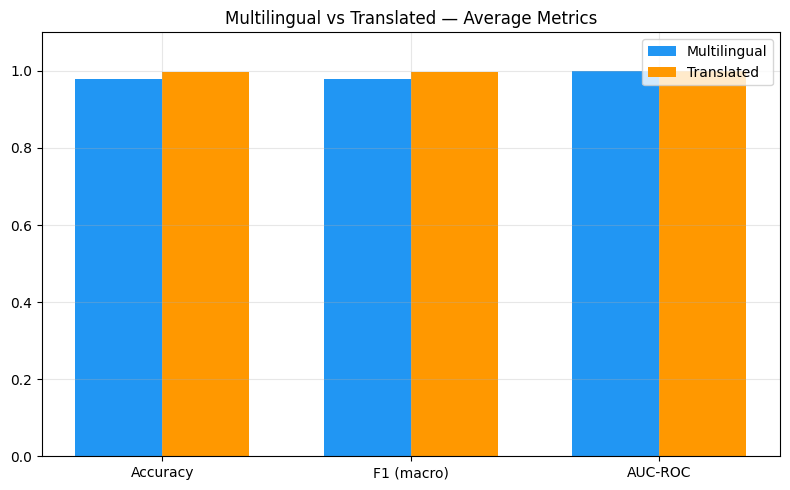

In [8]:
# Aggregate by approach
approach_summary = df_comp.groupby('Approach').agg({
    'Accuracy': 'mean',
    'F1 (macro)': 'mean',
    'AUC-ROC': 'mean',
    'Training Time (s)': 'mean',
}).reset_index()

print('\n=== APPROACH-LEVEL COMPARISON ===')
print(approach_summary.to_string(index=False))

# Which approach wins?
print('\n--- Approach Winner Per Metric ---')
for col in ['Accuracy', 'F1 (macro)', 'AUC-ROC']:
    winner = approach_summary.loc[approach_summary[col].idxmax(), 'Approach']
    print(f'{col}: {winner}')
fastest_approach = approach_summary.loc[approach_summary['Training Time (s)'].idxmin(), 'Approach']
print(f'Fastest: {fastest_approach}')

# Approach comparison bar
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(3)
width = 0.35
multi_vals = approach_summary[approach_summary['Approach'] == 'Multilingual'][['Accuracy', 'F1 (macro)', 'AUC-ROC']].values.flatten()
trans_vals = approach_summary[approach_summary['Approach'] == 'Translated'][['Accuracy', 'F1 (macro)', 'AUC-ROC']].values.flatten()

if len(multi_vals) == 3 and len(trans_vals) == 3:
    ax.bar(x - width/2, multi_vals, width, label='Multilingual', color='#2196F3')
    ax.bar(x + width/2, trans_vals, width, label='Translated', color='#FF9800')
    ax.set_xticks(x); ax.set_xticklabels(['Accuracy', 'F1 (macro)', 'AUC-ROC'])
    ax.set_ylim(0, 1.1); ax.legend(); ax.grid(True, alpha=0.3)
    ax.set_title('Multilingual vs Translated — Average Metrics')
    plt.tight_layout()
    plt.savefig(f'{COMP_DIR}/approach_summary.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Cannot plot — need results from both approaches.')

## Do both approaches agree on overall polarity?


In [9]:
print('=== Overall Brand Polarity Predictions ===\n')
polarity_all = {}
if polarity_multi:
    for k, v in polarity_multi.items():
        polarity_all[k] = v.get('overall_polarity', 'N/A')
        print(f'{k}: {v.get("overall_polarity", "N/A")}')
if polarity_trans:
    for k, v in polarity_trans.items():
        polarity_all[k] = v.get('overall_polarity', 'N/A')
        print(f'{k}: {v.get("overall_polarity", "N/A")}')

# Agreement
values = [v for v in polarity_all.values() if v != 'N/A']
if values:
    from collections import Counter
    counts = Counter(values)
    majority = counts.most_common(1)[0]
    print(f'\nMajority polarity: {majority[0]} ({majority[1]}/{len(values)} models agree)')
    agreement_pct = majority[1] / len(values) * 100
    print(f'Agreement: {agreement_pct:.0f}%')

=== Overall Brand Polarity Predictions ===

bert_bilstm: Neutral
xlm_roberta: Neutral
ground_truth: Neutral
bert_bilstm_en: Neutral
roberta_en: Neutral
ground_truth: Neutral

Majority polarity: Neutral (5/5 models agree)
Agreement: 100%


## Saving the comparison report


In [10]:
comparison_report = {
    'title': 'Cross-Approach Comparison: Multilingual vs Translated',
    'timestamp': pd.Timestamp.now().isoformat(),
    'models': {},
    'approach_summary': {},
    'rankings': {},
    'overall_polarity': polarity_all,
    'recommendation': '',
}

# Model details
for name, r in results.items():
    approach = 'Multilingual' if 'Multi' in name or 'XLM' in name else 'Translated'
    comparison_report['models'][name] = {
        'approach': approach,
        'metrics': r['metrics'],
        'epochs_trained': r['hyperparameters']['epochs_trained'],
    }

# Approach summary
for _, row in approach_summary.iterrows():
    comparison_report['approach_summary'][row['Approach']] = {
        'avg_accuracy': float(row['Accuracy']),
        'avg_f1_macro': float(row['F1 (macro)']),
        'avg_auc_roc': float(row['AUC-ROC']),
        'avg_training_time': float(row['Training Time (s)']),
    }

# Rankings
for metric in ['Accuracy', 'F1 (macro)', 'AUC-ROC']:
    comparison_report['rankings'][metric] = df_comp.sort_values(metric, ascending=False)['Model'].tolist()
comparison_report['rankings']['Speed'] = df_comp.sort_values('Training Time (s)')['Model'].tolist()

# Recommendation (automated based on results)
best_model = df_comp.sort_values('F1 (macro)', ascending=False).iloc[0]
comparison_report['recommendation'] = f"Best overall model: {best_model['Model']} ({best_model['Approach']} approach) with F1={best_model['F1 (macro)']:.4f} and training time {best_model['Training Time (s)']:.1f}s"

with open(f'{COMP_DIR}/cross_approach_comparison.json', 'w') as f:
    json.dump(comparison_report, f, indent=2)

print(f'Comparison report saved to: {COMP_DIR}/cross_approach_comparison.json')
print(f'\n{comparison_report["recommendation"]}')
print('\n✅ Notebook 3 complete. All comparison results saved.')

Comparison report saved to: /content/drive/MyDrive/ML_Sentiment_Analysis/Results_Comparison/cross_approach_comparison.json

Best overall model: RoBERTa (EN) (Translated approach) with F1=0.9962 and training time 138.6s

✅ Notebook 3 complete. All comparison results saved.
